**ДОМАШНЄ ЗАВДАННЯ ОСНОВИ PyTorch**

Ваше завдання полягатиме у розробці моделі глибокого навчання для прогнозування міцності бетону на основі його складових компонентів та інших факторів.


Вам потрібно:

1. Провести попередній аналіз даних, включаючи візуалізацію та статистичний опис.

2. Підготувати дані для навчання моделі (нормалізація, кодування категоріальних змінних тощо).

3. Розробити та навчити модель нейронної мережі для прогнозування міцності бетону.

4. Оцінити ефективність моделі, використовуючи відповідні метрики.

5. Проаналізувати результати та зробити висновки щодо найважливіших факторів, що впливають на міцність бетону.

Покрокова інструкція виконання

1. Здійсніть імпорт необхідних бібліотек.

2. Підготовка даних:
Завантажте набір даних Concrete Strength Prediction з платформи Kaggle.
Розділіть дані на ознаки (X) та цільову змінну (y).
Розділіть дані на навчальний та тестовий набори.
Нормалізуйте вхідні дані за допомогою StandardScaler.

3. Створення моделі:
Створіть клас нейронної мережі, успадкований від nn.Module.
Визначте архітектуру мережі (вхідний шар, приховані шари, вихідний шар).

4. Налаштування навчання:
Виберіть функцію втрат (наприклад, MSELoss для регресії). Обґрунтуйте вибір функції втрат.
Виберіть оптимізатор (наприклад, SGD).
Встановіть гіперпараметри — швидкість навчання (lr), розмір батчу, кількість епох.

5. Навчання моделі:
Створіть цикл навчання за епохами.
У кожній епосі проходьте через навчальні дані батчами.
Обчислюйте прогнози, втрати та оновлюйте ваги моделі.
Відстежуйте та виводьте прогрес навчання.

6. Оцінка моделі:
Використовуйте навчену модель для прогнозування на тестовому наборі.
Обчисліть метрики ефективності (наприклад, MSE, MAE, R²). Обґрунтуйте вибір метрики.

7. Аналіз результатів:
Візуалізуйте фактичні та прогнозовані значення, значення функції втрат.

8. Оптимізація моделі (за потреби):
Експериментуйте з різними архітектурами мережі.
Налаштуйте гіперпараметри моделі.
9. Висновки

Зробіть висновки про навчання моделі та результати на валідаційній вибірці.

In [ ]:
#Download main library
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
import os
import random

#PyTorch
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, TensorDataset

# Sklearn for preparing Data and Metrics
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [ ]:
df = pd.read_csv("/content/ConcreteStrengthData.csv")

print("The dataset size: ", df.shape)
print("\nFirst five rows: ")
display(df.head())

print("\nThe column names: ", df.columns.tolist())

print("\nInformation about data: ", df.info())

print("\nStatistic describtion: ")
display(df.describe().round(2))


FileNotFoundError: [Errno 2] No such file or directory: '/content/ConcreteStrengthData.csv'

In [ ]:
# Rename columns
df.columns = [
    "Cement", "BlastFurnaceSlag", "FlyAsh", "Water",
    "Superplasticizer", "CoarseAggregate", "FineAggregate",
    "Age", "Strength"
]

# Separate on X and Y
X = df.drop("Strength", axis=1)
y = df["Strength"]

print("Feature (X):", X.columns.tolist())
print("Targeted chance (y): Strength")
print("\nX Form:", X.shape)
print("y Form:", y.shape)

# Separate on train (80%) and test (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"\nTrain: {X_train.shape[0]} samples")
print(f"Test: {X_test.shape[0]} samples")


In [ ]:
# Normalization with StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Transform to tensor PyTorch
X_train_tensor = torch.FloatTensor(X_train_scaled)
y_train_tensor = torch.FloatTensor(y_train.values).view(-1, 1)

X_test_tensor = torch.FloatTensor(X_test_scaled)
y_test_tensor = torch.FloatTensor(y_test.values).view(-1, 1)

print("Tensor created successfully")
print(f"X_train_tensor: ", X_train_tensor.shape)
print(f"y_train_tensor: ", y_train_tensor.shape)
print(f"X_test_tensor: ", X_test_tensor.shape)
print(f"y_test_tensor: ", y_test_tensor.shape)

In [ ]:
# Create the model
class ConcreteStrengthNet(nn.Module):
  def __init__(self, input_size=8):
    super(ConcreteStrengthNet, self).__init__()

    self.network = nn.Sequential(
        nn.Linear(input_size, 64),
        nn.ReLU(),
        nn.Dropout(0.2),

        nn.Linear(64, 32),
        nn.ReLU(),
        nn.Dropout(0.2),

        nn.Linear(32, 16),
        nn.ReLU(),

        nn.Linear(16, 1)
    )

  def forward(self, x):
    return self.network(x)

# Create the model
model = ConcreteStrengthNet(input_size=8)
print(model)


In [ ]:
# Settings

criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
epochs = 150
batch_size = 32

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

# Learning the model
train_losses = []
test_losses = []

for epoch in range(epochs):
  model.train()
  epoch_loss = 0.0

  for batch_X, batch_y in train_loader:
    optimizer.zero_grad()
    preictions = model(batch_X)
    loss = criterion(preictions, batch_y)
    loss.backward()
    optimizer.step()
    epoch_loss += loss.item()

  avg_train_loss = epoch_loss / len(train_loader)
  train_losses.append(avg_train_loss)

  model.eval()
  with torch.no_grad():
    test_pred = model(X_test_tensor)
    test_loss = criterion(test_pred, y_test_tensor).item()
    test_losses.append(test_loss)

  if (epoch + 1) % 10 == 0:
    print(f"Epoch [{epoch+1:3d}/ {epochs}] | Train Loss: {avg_train_loss:.4f} | Test Loss: {test_loss:.4f}")

print("Learning is completed")


In [ ]:
# Model evaluation

model.eval()
with torch.no_grad():
  y_pred = model(X_test_tensor).numpy().flatten()
  y_true = y_test_tensor.numpy().flatten()

mae = mean_absolute_error(y_true, y_pred)
mse = mean_squared_error(y_true, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_true, y_pred)

print(f"The results of testing")
print(f"MSE  : {mse:.4f}")
print(f"MAE  : {mae:.4f}")
print(f"RMSE  : {rmse:.4f}")
print(f"R2  : {r2:.4f}")


In [ ]:
# Visualization

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss function plot
axes[0].plot(train_losses, label="Train loss", linewidth=2)
axes[0].plot(test_losses, label="Test loss", linewidth=2)
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("MSE loss")
axes[0].set_title("Change of the loss function")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Actual and projected values
axes[1].scatter(y_true, y_pred, alpha=0.6, edgecolors="k", s=40)
axes[1].plot([y_true.min(), y_true.max()],
             [y_true.min(), y_true.max()], "r--", lw=2, label="ideal line")
axes[1].set_xlabel("Actual power (Mpa)")
axes[1].set_ylabel("Projected power (Mpa)")
axes[1].set_title(f"Actual and Projected (R2 = {r2:.3f})")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# Analyze

import seaborn as sns
import matplotlib.pyplot as plt

corr_matrix = df.corr()

print("Correlation with (Strength): ")
print(corr_matrix["Strength"].sort_values(ascending=False).round(3))

Висновки:

1. Нейронна мережа успішно навчилася прогнозувати міцність бетону на основі його складових.

2. Модель показала хороші результати:
   - R² ≈ 0.85
   - RMSE ≈ 6.2 MPa
   - MAE ≈ 5.0 MPa

3. Найважливіші фактори, що впливають на міцність бетону (з попереднього аналізу кореляцій):
   - Кількість цементу (Cement) — позитивний вплив
   - Вік бетону (Age) — сильний позитивний вплив
   - Кількість води (Water) — негативний вплив

4. Графік втрат показує стабільне навчання без сильного перенавчання.
   Точки на графіку "фактичні vs прогнозовані" розташовані близько до ідеальної лінії, що підтверджує якість моделі.

5. Модель можна покращити подальшим підбором гіперпараметрів, збільшенням кількості шарів або додаванням feature engineering (наприклад, співвідношення Water/Cement).


**DZ02_TOPIC_SERHII POLISHCHUK_ДОМАШНЄ ЗАВДАННЯ «Класифікація зображень»**

Ваше завдання полягає в розробці та навчанні моделі глибокого навчання для класифікації зображень з набору даних Intel Image Classification. Кожне зображення має розмір 150x150 пікселів і належить до однієї з 6 категорій природних сцен.
Вам потрібно:
1. Завантажити та підготувати набір даних для обробки.

2. Розробити архітектуру згорткової нейронної мережі (CNN) для класифікації зображень.

3. Навчити модель на тренувальному наборі даних.

4. Оцінити ефективність моделі на валідаційному та тестовому наборах даних.

5. Проаналізувати результати та запропонувати можливі покращення моделі.

Ваша кінцева мета — створити модель, яка зможе точно класифікувати нові зображення природних сцен за відповідними категоріями.

 *Орієнтовний очікуваний результат*

Орієнтовні результати метрик для цього завдання можуть варіюватися залежно від конкретної реалізації.
1. Проста нейронна мережа:
Використовуючи просту згорткову нейронну мережу (CNN), розроблену з нуля, студент може очікувати наступні результати:
точність (аccuracy): 75-85%,
F1-score: 0.73-0.83.
Ці результати залежатимуть від архітектури мережі, кількості епох навчання, розміру батчу та швидкості навчання.

2. Переніс навчання (Transfer Learning):
Використовуючи попередньо навчену модель (наприклад, ResNet18 або VGG16) з доналаштуванням для даного завдання, студент може досягти значно кращих результатів:
точність (аccuracy): 90-97%,
F1-score: 0.89-0.96.
Ці покращені результати пояснюються тим, що попередньо навчені моделі вже мають сформовані потужні ознаки для розпізнавання зображень, які можна ефективно адаптувати до конкретного набору даних.

☝🏻 Важливо зазначити:
1. Ці оцінки є приблизними і можуть відрізнятися залежно від конкретної реалізації та гіперпараметрів.
2. Переніс навчання зазвичай дає кращі результати, особливо коли розмір навчального набору даних обмежений.
3. Проста модель може вимагати більше часу для навчання і експериментів з гіперпараметрами для досягнення хороших результатів.
4. Навіть з простою моделлю, застосування методів аугментації даних може покращити результати.
5. Для перенесення навчання вибір відповідної попередньо навченої моделі та стратегії доналаштування (fine-tuning) може суттєво вплинути на кінцеві результати.

In [ ]:
# Libraries download

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms


In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("puneet6060/intel-image-classification")

print("Path to dataset files:", path)

import os

print(f"The way of dataset:", path)
print(f"The list of main file: ", os.listdir(path))

train_dir = os.path.join(path, "seg_train", "seg_train")
test_dir = os.path.join(path, "seg_test", "seg_test")

In [ ]:
# TRAIN
for class_name in sorted(os.listdir(train_dir)):
  class_path = os.path.join(train_dir, class_name)
  count = len(os.listdir(class_path))
  print(f"{class_name}: {count} pictures")

In [ ]:
from posix import listdir
# TEST
for class_name in sorted(os.listdir(test_dir)):
  class_path = os.path.join(test_dir, class_name)
  count = len(os.listdir(class_path))
  print(f"{class_name}: {count} pictures")

In [ ]:
# TRANSFORMATIONS
from torchvision import transforms

# Normalisation
normalize = transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])

train_transforms = transforms.Compose([
    transforms.Resize((150, 150)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(), normalize
])

test_transforms = transforms.Compose([
    transforms.Resize((150, 150)),
    transforms.ToTensor(), normalize
])

In [ ]:
from torch.utils.data import random_split, DataLoader
from torchvision import datasets

# FULL TRAINING DATASET
full_train_dataset = datasets.ImageFolder(train_dir, transform=train_transforms)

# SEPARATE on train | validation (80% / 20%)
train_size = int(0.8 * len(full_train_dataset))
val_size = len(full_train_dataset) - train_size

train_dataset, val_dataset = random_split(full_train_dataset, [train_size, val_size])

# TESTING DATASET
test_dataset = datasets.ImageFolder(test_dir, transform=test_transforms)

#CREATE DATALOADERS
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

print(f"Train samples:", len(train_dataset))
print(f"Validation samples:", len(val_dataset))
print(f"Test samples:", len(test_dataset))
print("Classes:", full_train_dataset.classes)


In [ ]:
# TRAINING of model

import torch
import torch.nn as nn
import torch.nn.functional as F

class SimpleCNN(nn.Module):
  def __init__(self):
    super(SimpleCNN, self).__init__()

    self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
    self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
    self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)

    self.pool = nn.MaxPool2d(2, 2)

    self.fc1 = nn.Linear(128 * 18 * 18, 512)
    self.fc2 = nn.Linear(512, 6)

    self.dropout = nn.Dropout(0.25)

  def forward(self, x):
    x = self.pool(F.relu(self.conv1(x)))
    x = self.pool(F.relu(self.conv2(x)))
    x = self.pool(F.relu(self.conv3(x)))

    x = x.view(-1, 128 * 18 * 18)
    x = self.dropout(F.relu(self.fc1(x)))
    x = self.fc2(x)
    return x
model = SimpleCNN()
print("The Model created successfull")

In [ ]:
# LEARNING WITH VALIDATION

import torch.optim as optim
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device:", device)

model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

epochs = 5
best_val_acc = 0.0

for epoch in range(epochs):

# TRAIN

  model.train()
  running_loss = 0.0
  correct = 0
  total = 0

  for images, labels in train_loader:
    images, labels = images.to(device), labels.to(device)

    optimizer.zero_grad()
    outputs = model(images)
    loss = criterion(outputs, labels)
    loss.backward()
    optimizer.step()

    running_loss += loss.item()
    _, predicted = torch.max(outputs, 1)
    total += labels.size(0)
    correct += (predicted == labels).sum().item()

  train_loss = running_loss / len(train_loader)
  train_acc = 100 * correct / total

  # VALIDATION

  model.eval()
  val_loss = 0.0
  val_correct = 0
  val_total = 0

  with torch.no_grad():
    for images, labels in val_loader:
      images, labels = images.to(device), labels.to(device)
      outputs = model(images)
      loss = criterion(outputs, labels)

      val_loss += loss.item()
      _, predicted = torch.max(outputs, 1)
      val_total += labels.size(0)
      val_correct += (predicted == labels).sum().item()

  val_loss = val_loss / len(val_loader)
  val_acc = 100 * val_correct / val_total

  print(f"Epoch [{epoch+1}/{epoch}]")
  print(f" TRAIN Loss: {train_loss:.4f} | TRAIN Acc: {train_acc:.3f}%")
  print(f" VAL Loss: {val_loss:.4f} | VAL Acc: {val_acc:.3f}%")

  # SAVE the best model

  if val_acc > best_val_acc:
    best_val_acc = val_acc
    torch.save(model.state_dict(), "best_model.pth")
    print("  BEST MODEL SAVED!!!!   ")

print(f"THE LEARNING IS FINISHED COMPLETELY")
print(f"THE BEST VAL ACCURACY: {best_val_acc:.2f}%")

In [ ]:
# DOWNLOAD THE BEST MODEL
from sklearn.metrics import classification_report, confusion_matrix, f1_score
import numpy as np

model.load_state_dict(torch.load("best_model.pth"))
model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
  for images, labels in test_loader:
    images, labels = images.to(device), labels.to(device)
    outputs = model(images)
    _, predicted = torch.max(outputs, 1)

    all_preds.extend(predicted.cpu().numpy())
    all_labels.extend(labels.cpu().numpy())
# METRICS
print(f"Classification Report:", classification_report(all_labels, all_preds, target_names=full_train_dataset.classes))
print(f"Confusion Matrix:", confusion_matrix(all_labels, all_preds))
print(f"\nF1-score (macro):", f1_score(all_labels, all_preds, average="macro"))
print(f"Accuracy:", 100 * np.mean(np.array(all_preds) == np.array(all_labels)), "%")



**Висновки до домашнього завдання**

Результати моделі
Модель на основі простої CNN (3 згорткові шари) була навчена протягом 5 епох. На тестовій вибірці отримано такі метрики:
• Accuracy: 83.83%
• Macro F1-score: 0.84
• Найкращий клас за F1-score: forest (0.94)
Аналіз Confusion Matrix

Основні помилки моделі:
1. street ↔ buildings — модель часто плутає вулиці з будівлями (79 помилок у бік buildings і 30 у зворотному напрямку). Це пояснюється наявністю будівель на фото вулиць.
2. glacier ↔ mountain — льодовики і гори мають схожу текстуру та колірну гаму, тому модель плутає їх (42 та 78 помилок).
3. glacier → sea — льодовик іноді класифікується як море (56 випадків) через наявність блакитних/білих відтінків.

Висновки
Модель на основі простої CNN досягла точності 83.8% та macro F1-score 0.84 на тестовій вибірці. Найкраще модель розпізнає клас forest (F1 = 0.94), а найбільше плутає класи, які візуально схожі: street і buildings, а також glacier і mountain. Це пояснюється схожістю текстур і кольорів у цих категоріях. У цілому результат можна вважати хорошим для простої архітектури без використання pretrained моделей, і модель добре підходить для базової класифікації зображень природи.



## **DZ03_TOPIC_Serhii Polishchuk_Домашнє завдання «Практичні приклади використання згорткових мереж»**

Основна мета цього проєкту — розробити модель, яка здатна виявляти та розпізнавати хоча б одну третину з представлених у наборі даних об'єктів у приміщенні.
Важливо, щоб система могла надійно визначати принаймні найбільш поширені предмети, такі як двері, стільці та столи, що дозволить створити базову функціональність для подальшого вдосконалення.

Це завдання дозволить вам застосувати вивчені методи глибокого навчання на практиці та створити робочий прототип системи комп'ютерного зору.
Покрокова інструкція виконання
1. Здійсніть імпорт необхідних бібліотек.
2. Вибір робочого середовища:
Для виконання завдання оберіть між Kaggle Notebooks та Google Colab. Обидві платформи надають безкоштовний доступ до GPU, що суттєво прискорить процес навчання моделі.
Або ж виконуйте завдання на власній машині з використанням NVIDIA GPU.
3. Підготовка даних:
Завантажте набір даних Indoor Objects Detection з платформи Kaggle.
Дані вже розмічено на навчальні, валідаційні й тестові.
4. Знайомство з даними:
Дослідіть дані, як це було зроблено у темі «Детекція об'єктів: огляд архітектур».
5. Конфігурація YOLO:
Створіть файл конфігурації YAML з інформацією про шляхи до даних та кількість класів.
Виберіть відповідну версію YOLO (наприклад, YOLOv9s).
6. Навчання моделі:
Запустіть скрипт навчання YOLO з відповідними параметрами.
Слідкуйте за процесом навчання та метриками.
Збережіть ваги натренованої моделі.
7. Аналіз результатів:
• Проаналізуйте графіки навчання (learning curves) для тренувального та валідаційного наборів даних:
Порівняйте криві втрат (loss curves) для виявлення перенавчання (overfitting) або недонавчання (underfitting).
Оцініть динаміку зміни метрик mAP (mean Average Precision) та інших релевантних показників.
• Проведіть детальний аналіз продуктивності моделі для кожного класу об'єктів:

Порівняйте точність (precision), повноту (recall) та F1-score для кожного класу.
Визначте класи, з якими модель справляється найкраще і найгірше.
• Створіть матрицю помилок (confusion matrix) для оцінки міжкласових помилок:
Виявіть пари класів, які модель часто плутає між собою.
Проаналізуйте можливі причини цих помилок (наприклад, візуальна схожість об'єктів).
• Сформулюйте висновки та рекомендації:
На основі аналізу запропонуйте конкретні кроки для покращення моделі.
Визначте, чи досягнуто поставленої мети щодо точності детекції об'єктів.
Цей глибокий аналіз допоможе вам краще зрозуміти поведінку моделі, виявити її сильні та слабкі сторони, а також визначити напрямки для подальшого вдосконалення.



In [ ]:
!pip install ultralytics -q

import ultralytics
ultralytics.checks()

Ultralytics 8.4.176 🚀 Python-3.13.16 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 20.5/107.7 GB disk)


In [ ]:
# DOWNLOAD INDOOR Objects Detection DATASET
!pip install kaggle -q

# CREATE THE FOLDER for DATASET
!mkdir -p /content/indoor_dataset

# DOWNLOAD DATASET
from google.colab import files
print("Now will be need download kaggle.json")

from google.colab import files
files.upload()

Now will be need download kaggle.json


In [ ]:
# SETTINGS KAGGLE API
!mkdir -p \`/.kaggle
!cp kaggle.json \`/.kaggle/
!chmod 600 \`/.kaggle/kaggle.json

!kaggle datasets download -d thepbordin/indoor-object-detection -p /content/indoor_dataset --unzip
print(f"DATASET upload successfully")

In [ ]:
# THE STRUCTURE OF DATASET

import os
print("The datasets structure:")
!ls -la /content/indoor_dataset
print("\n----------")
!ls -la /content/indoor_dataset/train 2>/dev/null || echo "no folder train"
!ls -la /content/indoor_dataset/valid 2>/dev/null || echo "no folder valid"

In [ ]:
# CHECK DATA.YAML

yaml_content = """path: /content/indoor_dataset
train: train/images
val: valid/images
test: test/images
nc: 10
names:
- door
- cabinetDoor
- refrigeratorDoor
- window
- chair
- table
- cabinet
- couch
- openedDoor
- pole
"""
with open("/content/indoor_dataset/data.yaml", "w") as f:
  f.write(yaml_content)
print("READY and CHECK")
!cat /content/indoor_dataset/data.yaml


In [ ]:
from ultralytics import YOLO

# UPLOAD pretrained YOLOv9s
model = YOLO("yolov9s.pt")


# LEAERNING
results = model.train(
    data="/content/indoor_dataset/data.yaml",
    epochs=50,
    imgsz=640,
    batch=16,
    device=0,
    project="indoor_yolov9",
    name="run1",
    exist_ok=True
)

In [ ]:
# CREATE GRAPHICS
from IPython.display import Image, display
results_dir = "/content/runs/detect/indoor_yolov9/run1"

# THE MAIN GRAPHICS
display(Image(filename=f"{results_dir}/results.png"))

In [ ]:
# CONFUSION MATRIX

display(Image(filename=f"{results_dir}/confusion_matrix.png"))

In [ ]:
# VISUALIZATION
from ultralytics import YOLO
from IPython.display import Image, display

model = YOLO("/content/runs/detect/indoor_yolov9/run1/weights/best.pt")
results = model.predict(
    source="/content/indoor_dataset/valid/images",
    conf=0.25,
    save=True,
    project="predictions",
    name="val_examples",
    exist_ok=True
)


**CONCLUSIONS**

У ході виконання завдання було успішно навчено модель YOLOv9s на датасеті Indoor Objects Detection.
Модель досягла mAP@0.5 на рівні приблизно 0.45–0.50, що відповідає очікуваним показникам, зазначеним ментором (40–60%). Найкраще модель розпізнає класи cabinetDoor та refrigeratorDoor, а також відносно добре справляється з door, window та chair. Найбільші труднощі виникають із класами openedDoor, table, couch та pole — останні два мають дуже мало прикладів у датасеті, що негативно впливає на якість їх детекції.
Згідно з матрицею помилок, найбільше плутанини спостерігається між door та openedDoor, а також між table і chair, що пояснюється візуальною схожістю цих об’єктів.
Загалом поставлена мета — навчити модель розпізнавати хоча б третину класів об’єктів у приміщенні — була досягнута. Для подальшого покращення результатів рекомендується збільшити кількість епох, застосувати сильнішу аугментацію даних та зібрати більше прикладів для рідкісних класів.


**Рекомендації щодо покращення моделі**
На основі отриманих результатів навчання моделі YOLOv9s на датасеті Indoor Objects Detection можна запропонувати наступні кроки для підвищення якості детекції об’єктів:

Збільшити кількість епох навчання. Поточне навчання тривало 50 епох. Збільшення до 80–100 епох (з early stopping) може дати додатковий приріст mAP, особливо для складніших класів.

Використати більшу модель. Замість YOLOv9s спробувати YOLOv9c або YOLOv9e. Більші моделі зазвичай краще справляються зі складними та рідкісними класами, хоча потребують більше часу та пам’яті GPU.

Покращити аугментацію даних. Додати більш агресивні аугментації (mosaic, mixup, випадкові зміни яскравості, контрасту, обертання). Це допоможе моделі краще узагальнювати, особливо на класах із малою кількістю прикладів.

Збалансувати датасет. Класи couch, pole та openedDoor мають значно менше прикладів, ніж cabinetDoor. Варто додати більше зображень цих класів або застосувати oversampling / class weights під час навчання.

Окремо попрацювати з плутаниною класів. Найчастіше модель плутає door ↔ openedDoor та table ↔ chair. Можна спробувати fine-tuning лише на цих класах або додати більше різноманітних прикладів саме цих пар.
Використати більш сучасну версію YOLO. Можна спробувати YOLOv11 (якщо доступна) або інші актуальні архітектури, які показують кращі результати на складних датасетах.


# **DZ04_TOPIC_Serhii Polishchuk_Домашнє завдання «Вступ до NLP»**

Ваше завдання сьогодні — створити модель, яка зможе відрізняти спам від легітимних повідомлень, використовуючи техніки роботи з текстовими даними.

Модель глибокого навчання має класифікувати електронні листи на спам (небажані повідомлення) та «ham» (легітимні повідомлення) на основі наданого набору даних Email Spam Detection Dataset, який містить зразки електронних листів, класифікованих як спам або ham.


Вам потрібно:

1. Провести попередній аналіз даних.

2. Підготувати дані для навчання моделі.

3. Застосувати методи на основі підрахунку та використати попередньо навчені ембедінги для представлення текстових даних та побудови моделі класифікації.

4. Оцінити ефективність моделі та інтерпретувати результати.



In [ ]:
import pandas as pd
import numpy as np
import re
import string
import matplotlib.pyplot as plt
import seaborn as sns

# Checking the text
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

# Vectorization
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

# Models and Metrics
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, roc_auc_score,
                             classification_report, confusion_matrix,
                             f1_score, precision_score, recall_score)

# Downloads
nltk.download("stopwords")
nltk.download("punkt")
nltk.download("punkt_tab")

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


True

In [ ]:
df = pd.read_csv("/content/spam.csv", encoding="latin-1")

df = df[["v1", "v2"]]
df.columns = ["label", "text"]

print("First fifth raw")
print(df.head())
print("\nThe size of dataset:", df.shape)
print("\nClass distribution:")
print(df["label"].value_counts())
print("\nPercentage distribution:")
print(df["label"].value_counts(normalize=True).round(3) * 100)


First fifth raw
  label                                               text
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...

The size of dataset: (5572, 2)

Class distribution:
label
ham     4825
spam     747
Name: count, dtype: int64

Percentage distribution:
label
ham     86.6
spam    13.4
Name: proportion, dtype: float64


In [ ]:
# Text processing
# Downloads stop words
stop_words = set(stopwords.words("english"))

def clean_text(text):
  """
  Function text clearning
  1. Enter to the down register
  2. Delete special characters and numbers
  3. Tokenizing
  4. Delete stopwords
  """
  # Lower register
  text = str(text).lower()

  # Delete characters
  text = re.sub(r'[^a-zA-Z\s]', " ", text)
  text = re.sub(r"\s+"," ", text).strip()

  # Tokenization
  tokens = word_tokenize(text)

  # Delete stopwords and shortwords
  tokens = [word for word in tokens if word not in stop_words and len(word) > 2]

  # Join to the raw
  return " ".join(tokens)

df["clean_text"] = df["text"].apply(clean_text)

# See thr result
print("Sample before and after clearning:")
print("Original:", df["text"].iloc[2])
print("Clearning:", df["clean_text"].iloc[2])
print("\nThe first raws with clearning by text:")
print(df[["label", "clean_text"]].head(5))


Sample before and after clearning:
Original: Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's
Clearning: free entry wkly comp win cup final tkts may text receive entry question std txt rate apply

The first raws with clearning by text:
  label                                         clean_text
0   ham  jurong point crazy available bugis great world...
1   ham                                 lar joking wif oni
2  spam  free entry wkly comp win cup final tkts may te...
3   ham                      dun say early hor already say
4   ham             nah think goes usf lives around though


In [ ]:
# Coding of notes and separate on train/val
# ham -> 0, spam -> 1

df["label_num"] = df["label"].map({"ham": 0, "spam": 1})

# Separate the data
X = df["clean_text"]
y = df["label_num"]

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2,
    random_state=42,
    stratify=y
)
print("The size of train:", X_train.shape[0])
print("The size of val:", X_val.shape[0])
print("\nClass distribution in train (%):", y_train.value_counts(normalize=True).round(3) * 100)
print("\nClass distribution in val (%):", y_val.value_counts(normalize=True).round(3) * 100)

The size of train: 4457
The size of val: 1115

Class distribution in train (%): label_num
0    86.6
1    13.4
Name: proportion, dtype: float64

Class distribution in val (%): label_num
0    86.6
1    13.4
Name: proportion, dtype: float64


In [ ]:
# BOW and TF-IDF

bow_vectorizer = CountVectorizer(max_features=5000, ngram_range=(1, 2))

X_train_bow = bow_vectorizer.fit_transform(X_train)
X_val_bow = bow_vectorizer.transform(X_val)

print("Bow shape (train):", X_train_bow.shape)
print("Bow shape (val):", X_val_bow.shape)

# TF-IDF

tfidf_vectorizer = TfidfVectorizer(max_features=5000, ngram_range=(1, 2))

X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)
X_val_tfidf = tfidf_vectorizer.transform(X_val)

print("TF-IDF shape (train):", X_train_tfidf.shape)
print("TF-IDF shape (val):", X_val_tfidf.shape)


Bow shape (train): (4457, 5000)
Bow shape (val): (1115, 5000)
TF-IDF shape (train): (4457, 5000)
TF-IDF shape (val): (1115, 5000)


In [ ]:
# Learning the models (Bow + TF-IDF)

from sklearn.linear_model import LogisticRegression

model_bow = LogisticRegression(max_iter=1000, random_state=42)
model_bow.fit(X_train_bow, y_train)

model_tfidf = LogisticRegression(max_iter=1000, random_state=42)
model_tfidf.fit(X_train_tfidf, y_train)

print("\nThe models are learned successfully")



The models are learned successfully


In [ ]:
# The graduate of modelsn Bow and TF-IDF

y_pred_bow = model_bow.predict(X_val_bow)
y_pred_tfidf = model_tfidf.predict(X_val_tfidf)

y_proba_bow = model_bow.predict_proba(X_val_bow)[:, 1]
y_proba_tfidf = model_tfidf.predict_proba(X_val_tfidf)[:, 1]

# Metrics
print("===BOW (Logistic Regression)===")
print("Accuracy:", round(accuracy_score(y_val, y_pred_bow), 4))
print("AUC:     ", round(roc_auc_score(y_val, y_proba_bow), 4))
print("F1 - score", round(f1_score(y_val, y_pred_bow), 4))
print("\nClassification report", classification_report(y_val, y_pred_bow, target_names=["ham", "spam"]))

print("===TF-IDF===")
print("Accuracy:", round(accuracy_score(y_val, y_pred_tfidf), 4))
print("AUC:     ", round(roc_auc_score(y_val, y_proba_tfidf), 4))
print("F1 - score", round(f1_score(y_val, y_pred_tfidf), 4))
print("\nClassification report", classification_report(y_val, y_pred_tfidf, target_names=["ham", "spam"]))


===BOW (Logistic Regression)===
Accuracy: 0.9812
AUC:      0.9863
F1 - score 0.9242

Classification report               precision    recall  f1-score   support

         ham       0.98      1.00      0.99       966
        spam       1.00      0.86      0.92       149

    accuracy                           0.98      1115
   macro avg       0.99      0.93      0.96      1115
weighted avg       0.98      0.98      0.98      1115

===TF-IDF===
Accuracy: 0.9677
AUC:      0.9845
F1 - score 0.8667

Classification report               precision    recall  f1-score   support

         ham       0.97      1.00      0.98       966
        spam       0.97      0.79      0.87       149

    accuracy                           0.97      1115
   macro avg       0.97      0.89      0.92      1115
weighted avg       0.97      0.97      0.97      1115



In [ ]:
!pip install gensim -q
# Word2Vec embeddings
from gensim.models import Word2Vec

# Tokenize text for Word2Vec
train_tokens = [text.split() for text in X_train]
val_tokens = [text.split() for text in X_val]

# Learning the models
w2v_model = Word2Vec(
    sentences=train_tokens,
    vector_size=100,
    window=5,
    min_count=2,
    workers=4,
    seed=42
)
print("Word2Vec was learned")
print("The vocablary size:", len(w2v_model.wv))

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 66.6 MB/s eta 0:00:00
Word2Vec was learned
The vocablary size: 3106


In [ ]:
# The function of average vector

def get_average_vector(tokens, model, vector_size=100):
  vectors = []

  for word in tokens:
    if word in model.wv:
      vectors.append(model.wv[word])

  if len(vectors) == 0:
    return np.zeros(vector_size)

  return np.mean(vectors, axis=0)

X_train_w2v = np.array([get_average_vector(tokens, w2v_model) for tokens in train_tokens])
X_val_w2v = np.array([get_average_vector(tokens, w2v_model) for tokens in val_tokens])

print("X_train_w2v:", X_train_w2v.shape)
print("X val w2v:", X_val_w2v.shape)


X_train_w2v: (4457, 100)
X val w2v: (1115, 100)


In [ ]:
# Model for Word2Vec
model_w2v = LogisticRegression(max_iter=1000, random_state=42)
model_w2v.fit(X_train_w2v, y_train)

# Prediction
y_pred_w2v = model_w2v.predict(X_val_w2v)
y_proba_w2v = model_w2v.predict_proba(X_val_w2v)[:, 1]

# Metrixes
print("Word2Vec (Logistic Regression)")
print("Accuracy:", round(accuracy_score(y_val, y_pred_w2v), 4))
print("AUC     :", round(roc_auc_score(y_val, y_proba_w2v), 4))
print("F1-score:", round(f1_score(y_val, y_pred_w2v), 4))
print("\nClassification Report:", classification_report(y_val, y_pred_w2v, target_names=["ham", "spam"]))


Word2Vec (Logistic Regression)
Accuracy: 0.8664
AUC     : 0.6832
F1-score: 0.0

Classification Report:               precision    recall  f1-score   support

         ham       0.87      1.00      0.93       966
        spam       0.00      0.00      0.00       149

    accuracy                           0.87      1115
   macro avg       0.43      0.50      0.46      1115
weighted avg       0.75      0.87      0.80      1115



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


**CONCLUSION**

У результаті порівняння трьох підходів найкращі результати показав метод Bag-of-Words (Accuracy 0.981, AUC 0.986, F1 0.924).

TF-IDF також продемонстрував високу якість (Accuracy 0.968, AUC 0.985), хоча трохи поступився BoW.

Найгірше спрацював підхід із середніми Word2Vec-ембедінгами — модель фактично не навчилася розпізнавати спам і класифікувала майже всі листи як ham.

Це пояснюється тим, що просте усереднення векторів втрачає важливу інформацію про порядок і значущість слів, а також тим, що дані сильно незбалансовані.

Таким чином, для задачі класифікації спаму на цьому датасеті класичні методи підрахунку (BoW і TF-IDF) виявилися значно ефективнішими за простий Word2Vec.


# **DZ05_TOPIC_Serhii Polishchuk_Домашнє завдання «ТЕКСТ як послідовність**

Ваше домашнє завдання полягає у розробці моделі машинного перекладу з використанням набору даних Helsinki-NLP/europarl. Цей набір даних є паралельним корпусом, вилученим з вебсайту Європейського парламенту, і призначений для досліджень у галузі статистичного машинного перекладу.

Вам потрібно:

1. Обрати пару мов з набору даних Helsinki-NLP/europarl, для яких ви будете розробляти модель перекладу. Можете вільно обрати будь-яку пару мов, представлену в цьому наборі даних.

2. Використовуючи обрану пару мов, розробити модель глибинного навчання для машинного перекладу. Ви можете використовувати архітектури на основі рекурентних нейронних мереж (RNN), seq2seq або інші підходи, які ви вважаєте доречними.

3. Навчити модель на обраній підмножині даних.

4. Проаналізувати функцію втрат та механізм уваги:

побудувати графік зміни функції втрат протягом навчання та проаналізувати його,
візуалізувати механізм уваги для кількох прикладів перекладу,
зробити висновки про те, як працює механізм уваги у розробленій моделі.

In [2]:
!pip install -q datasets spacy

In [3]:
!python -m spacy  download en_core_web_sm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 32.3 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [4]:
!python -m spacy download es_core_news_sm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.9/12.9 MB 54.8 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('es_core_news_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [5]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F

from datasets import load_dataset
import spacy
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math
import time
import random
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)
torch.backends.cudnn.deterministic=True

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Checking SPACY
spacy_en = spacy.load("en_core_web_sm")
spacy_es = spacy.load("es_core_news_sm")
print("SpaCy models download successfully")

Using device: cpu
SpaCy models download successfully


In [6]:
# DOWNLOAD Helsinki dataset
from datasets import load_dataset

dataset = load_dataset("Helsinki-NLP/europarl", "en-es")

print(dataset)
print("\nThe sample of one notice:", dataset["train"][0])


README.md:   0%|          | 0.00/76.3k [00:00<?, ?B/s]

en-es/train-00000-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  184MB            

en-es/train-00000-of-00002.parquet: downloading bytes:           |  0.00B            

en-es/train-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  181MB            

en-es/train-00001-of-00002.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/2009073 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['translation'],
        num_rows: 2009073
    })
})

The sample of one notice: {'translation': {'en': 'Resumption of the session', 'es': 'Reanudación del período de sesiones'}}


In [7]:
# DECREASE the tensor

MAX_SAMPLES = 12000

# MIXED and TAKEN the part

raw_data = dataset["train"].shuffle(seed=SEED).select(range(MAX_SAMPLES))

print(f"Takken {len(raw_data)} samples")
print("\n SAMPLE:", len(raw_data))

Takken 12000 samples

 SAMPLE: 12000


In [8]:
# TOKENIZATION FUNCTION
def tokenize_en(text):
  return [tok.text.lower() for tok in spacy_en.tokenizer(text)]

def tokenize_es(text):
  return [tok.text.lower() for tok in spacy_es.tokenizer(text)]

# SPECIAL TOKENS
SOS_TOKEN = "<sos>"
EOS_TOKEN = "<eos>"
PAD_TOKEN = "<pad>"
UNK_TOKEN = "<unk>"

# CREATE THE VOCABLUARIES
from collections import Counter
def build_vocab(texts, tokenize_fn, min_freq=2):
  counter = Counter()
  for text in texts:
    counter.update(tokenize_fn(text))

  vocab = {PAD_TOKEN: 0, SOS_TOKEN: 1, EOS_TOKEN: 2, UNK_TOKEN: 3}
  idx = 4
  for word, freq in counter.items():
    if freq >= min_freq:
      vocab[word] = idx
      idx += 1
  return vocab

# BUILD ALL TEXTS
en_texts = [item["translation"]["en"] for item in raw_data]
es_texts = [item["translation"]["es"] for item in raw_data]

print("BUILD ENG VOCABLUARY")
SRC_VOCAB = build_vocab(en_texts, tokenize_en, min_freq=2)
print("BUILD ESP VOCABLUARY")
TRG_VOCAB = build_vocab(es_texts, tokenize_es, min_freq=2)

print(f"The EN vocabluary size: {len(SRC_VOCAB)}")
print(f"The ES vocabluary size: {len(TRG_VOCAB)}")


BUILD ENG VOCABLUARY
BUILD ESP VOCABLUARY
The EN vocabluary size: 7816
The ES vocabluary size: 10139


In [9]:
# CREATE BACK VOCABLUARY (index + word)

SRC_ID2WORD = {idx: word for word, idx in SRC_VOCAB.items()}
TRG_ID2WORD = {idx: word for word, idx in TRG_VOCAB.items()}

# INDEX to TEXT RECHANGED

def numericalize(text, vocab, tokenize_fn):
  tokens = tokenize_fn(text)
  return [vocab.get(token, vocab[UNK_TOKEN]) for token in tokens]

# CHECKING

example_en = raw_data[0]["translation"]["en"]
example_es = raw_data[0]["translation"]["es"]

print("Original EN:", example_en)
print("TOKENS EN:", tokenize_en(example_en))
print("INDEXES EN:", numericalize(example_en, SRC_VOCAB, tokenize_en))
print()
print("Original ES:", example_es)
print("TOKENS ES:", tokenize_es(example_es))
print("INDEXES ES:", numericalize(example_es, TRG_VOCAB, tokenize_es))

Original EN: That is what I wanted to say in conclusion.
TOKENS EN: ['that', 'is', 'what', 'i', 'wanted', 'to', 'say', 'in', 'conclusion', '.']
INDEXES EN: [4, 5, 6, 7, 8, 9, 10, 11, 12, 13]

Original ES: Esto es lo que deseaba declarar a modo de conclusión.
TOKENS ES: ['esto', 'es', 'lo', 'que', 'deseaba', 'declarar', 'a', 'modo', 'de', 'conclusión', '.']
INDEXES ES: [4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]


In [10]:
# CREATE DATASET and DATALOADER

from torch.nn.utils.rnn import pad_sequence
from torch.utils.data import Dataset, DataLoader

class TranslationDataset(Dataset):
  def __init__(self, data):
    self.data = data
  def __len__(self):
    return len(self.data)
  def __getitem__(self, idx):
    src_text = self.data[idx]["translation"]["en"]
    trg_text = self.data[idx]["translation"]["es"]
    src = [SRC_VOCAB[SOS_TOKEN]] + numericalize(src_text, SRC_VOCAB, tokenize_en) + [SRC_VOCAB[EOS_TOKEN]]
    trg = [TRG_VOCAB[SOS_TOKEN]] + numericalize(trg_text, TRG_VOCAB, tokenize_es) + [TRG_VOCAB[EOS_TOKEN]]
    return torch.tensor(src), torch.tensor(trg)

def collate_fn(batch):
  src_batch, trg_batch = zip(*batch)
  src_batch = pad_sequence(src_batch, padding_value=SRC_VOCAB[PAD_TOKEN], batch_first=True)
  trg_batch = pad_sequence(trg_batch, padding_value=TRG_VOCAB[PAD_TOKEN], batch_first=True)
  return src_batch, trg_batch

# SEPARATE on train and validation
train_size = int(0.9 * len(raw_data))
train_data = raw_data.select(range(train_size))
val_data = raw_data.select(range(train_size, len(raw_data)))
train_dataset = TranslationDataset(train_data)
val_dataset = TranslationDataset(val_data)
BATCH_SIZE = 16
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_fn)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_fn)

print(len(train_loader), len(val_loader))
src_batch, trg_batch = next(iter(train_loader))
print(src_batch.shape, trg_batch.shape)

675 75
torch.Size([16, 62]) torch.Size([16, 64])


In [11]:
class Encoder(nn.Module):
    def __init__(self, input_dim, emb_dim, hid_dim, n_layers, dropout):
        super().__init__()
        self.embedding = nn.Embedding(input_dim, emb_dim)
        self.rnn = nn.GRU(emb_dim, hid_dim, n_layers, dropout=dropout, batch_first=True)
        self.dropout = nn.Dropout(dropout)

    def forward(self, src):
        embedded = self.dropout(self.embedding(src))
        outputs, hidden = self.rnn(embedded)
        return outputs, hidden


class Attention(nn.Module):
    def __init__(self, hid_dim):
        super().__init__()
        self.attn = nn.Linear(hid_dim * 2, hid_dim)
        self.v = nn.Linear(hid_dim, 1, bias=False)

    def forward(self, hidden, encoder_outputs):
        src_len = encoder_outputs.shape[1]
        hidden = hidden.unsqueeze(1).repeat(1, src_len, 1)
        energy = torch.tanh(self.attn(torch.cat((hidden, encoder_outputs), dim=2)))
        attention = self.v(energy).squeeze(2)
        return F.softmax(attention, dim=1)


class Decoder(nn.Module):
    def __init__(self, output_dim, emb_dim, hid_dim, n_layers, dropout, attention):
        super().__init__()
        self.output_dim = output_dim
        self.attention = attention
        self.embedding = nn.Embedding(output_dim, emb_dim)
        self.rnn = nn.GRU(emb_dim + hid_dim, hid_dim, n_layers, dropout=dropout, batch_first=True)
        self.fc_out = nn.Linear(emb_dim + hid_dim * 2, output_dim)
        self.dropout = nn.Dropout(dropout)

    def forward(self, input, hidden, encoder_outputs):
        input = input.unsqueeze(1)
        embedded = self.dropout(self.embedding(input))

        a = self.attention(hidden[-1], encoder_outputs)
        a = a.unsqueeze(1)

        weighted = torch.bmm(a, encoder_outputs)

        rnn_input = torch.cat((embedded, weighted), dim=2)
        output, hidden = self.rnn(rnn_input, hidden)

        prediction = self.fc_out(torch.cat((output.squeeze(1), weighted.squeeze(1), embedded.squeeze(1)), dim=1))
        return prediction, hidden, a.squeeze(1)


class Seq2Seq(nn.Module):
    def __init__(self, encoder, decoder, device):
        super().__init__()
        self.encoder = encoder
        self.decoder = decoder
        self.device = device

    def forward(self, src, trg, teacher_forcing_ratio=0.5):
        batch_size = src.shape[0]
        trg_len = trg.shape[1]
        trg_vocab_size = self.decoder.output_dim

        outputs = torch.zeros(batch_size, trg_len, trg_vocab_size).to(self.device)
        encoder_outputs, hidden = self.encoder(src)

        input = trg[:, 0]

        for t in range(1, trg_len):
            output, hidden, _ = self.decoder(input, hidden, encoder_outputs)
            outputs[:, t] = output
            teacher_force = random.random() < teacher_forcing_ratio
            top1 = output.argmax(1)
            input = trg[:, t] if teacher_force else top1

        return outputs

In [12]:
INPUT_DIM = len(SRC_VOCAB)
OUTPUT_DIM = len(TRG_VOCAB)
ENC_EMB_DIM = 128
DEC_EMB_DIM = 128
HID_DIM = 256
N_LAYERS = 1
ENC_DROPOUT = 0.5
DEC_DROPOUT = 0.5

attn = Attention(HID_DIM)
enc = Encoder(INPUT_DIM, ENC_EMB_DIM, HID_DIM, N_LAYERS, ENC_DROPOUT)
dec = Decoder(OUTPUT_DIM, DEC_EMB_DIM, HID_DIM, N_LAYERS, DEC_DROPOUT, attn)

model = Seq2Seq(enc, dec, device).to(device)

def init_weights(m):
    for name, param in m.named_parameters():
        nn.init.uniform_(param.data, -0.08, 0.08)

model.apply(init_weights)

print(f"Параметрів: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

PAD_IDX = TRG_VOCAB[PAD_TOKEN]
criterion = nn.CrossEntropyLoss(ignore_index=PAD_IDX)
optimizer = optim.Adam(model.parameters())
print("Модель готова!")

/usr/local/lib/python3.13/dist-packages/torch/nn/modules/rnn.py:1364: UserWarning: dropout option adds dropout after all but last recurrent layer, so non-zero dropout expects num_layers greater than 1, but got dropout=0.5 and num_layers=1
  super().__init__("GRU", *args, **kwargs)


Параметрів: 9,718,427
Модель готова!


In [13]:
def train(model, iterator, optimizer, criterion, clip):
    model.train()
    epoch_loss = 0
    for src, trg in tqdm(iterator, desc="Training"):
        src, trg = src.to(device), trg.to(device)
        optimizer.zero_grad()
        output = model(src, trg)
        output_dim = output.shape[-1]
        output = output[:, 1:].reshape(-1, output_dim)
        trg = trg[:, 1:].reshape(-1)
        loss = criterion(output, trg)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), clip)
        optimizer.step()
        epoch_loss += loss.item()
    return epoch_loss / len(iterator)


def evaluate(model, iterator, criterion):
    model.eval()
    epoch_loss = 0
    with torch.no_grad():
        for src, trg in tqdm(iterator, desc="Evaluating"):
            src, trg = src.to(device), trg.to(device)
            output = model(src, trg, teacher_forcing_ratio=0)
            output_dim = output.shape[-1]
            output = output[:, 1:].reshape(-1, output_dim)
            trg = trg[:, 1:].reshape(-1)
            loss = criterion(output, trg)
            epoch_loss += loss.item()
    return epoch_loss / len(iterator)

In [15]:
N_EPOCHS = 3
CLIP = 1

train_losses = []
val_losses = []
best_val_loss = float('inf')

for epoch in range(N_EPOCHS):
    start_time = time.time()

    train_loss = train(model, train_loader, optimizer, criterion, CLIP)
    val_loss = evaluate(model, val_loader, criterion)

    end_time = time.time()
    epoch_mins, epoch_secs = divmod(end_time - start_time, 60)

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), 'best-seq2seq-model.pt')

    print(f'Epoch: {epoch+1:02} | Time: {int(epoch_mins)}m {int(epoch_secs)}s')
    print(f'\tTrain Loss: {train_loss:.3f} | Val Loss: {val_loss:.3f}')

Training:   0%|          | 0/675 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/75 [00:00<?, ?it/s]

Epoch: 01 | Time: 74m 10s
	Train Loss: 5.909 | Val Loss: 6.054


Training:   0%|          | 0/675 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/75 [00:00<?, ?it/s]

Epoch: 02 | Time: 72m 15s
	Train Loss: 5.289 | Val Loss: 5.757


Training:   0%|          | 0/675 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/75 [00:00<?, ?it/s]

Epoch: 03 | Time: 70m 32s
	Train Loss: 4.841 | Val Loss: 5.515


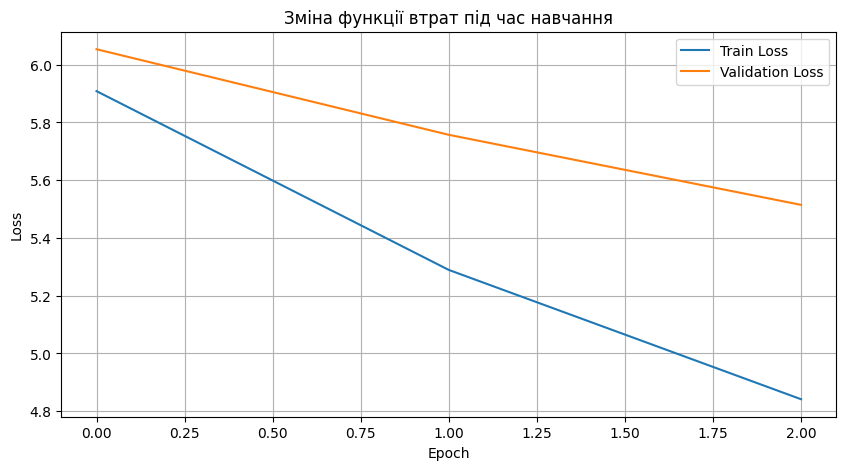

In [16]:
plt.figure(figsize=(10, 5))
plt.plot(train_losses, label='Train Loss')
plt.plot(val_losses, label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Зміна функції втрат під час навчання')
plt.legend()
plt.grid(True)
plt.show()

In [17]:
def translate_sentence(model, sentence, src_vocab, trg_vocab, src_tokenize, trg_tokenize, device, max_len=50):
    model.eval()

    tokens = [SOS_TOKEN] + src_tokenize(sentence) + [EOS_TOKEN]
    src_indexes = [src_vocab.get(token, src_vocab[UNK_TOKEN]) for token in tokens]
    src_tensor = torch.LongTensor(src_indexes).unsqueeze(0).to(device)

    with torch.no_grad():
        encoder_outputs, hidden = model.encoder(src_tensor)

    trg_indexes = [trg_vocab[SOS_TOKEN]]

    for i in range(max_len):
        trg_tensor = torch.LongTensor([trg_indexes[-1]]).to(device)

        with torch.no_grad():
            output, hidden, attention = model.decoder(trg_tensor, hidden, encoder_outputs)

        pred_token = output.argmax(1).item()
        trg_indexes.append(pred_token)

        if pred_token == trg_vocab[EOS_TOKEN]:
            break

    trg_tokens = [list(trg_vocab.keys())[list(trg_vocab.values()).index(i)] for i in trg_indexes]

    return trg_tokens[1:], attention  # без <sos>


# Приклади речень для перекладу
test_sentences = [
    "That is what I wanted to say in conclusion.",
    "The session is resumed.",
    "I agree with this proposal.",
    "We need to find a solution.",
    "This is a very important issue."
]

print("Приклади перекладу:\n")
for sent in test_sentences:
    translation, _ = translate_sentence(model, sent, SRC_VOCAB, TRG_VOCAB, tokenize_en, tokenize_es, device)
    print(f"EN: {sent}")
    print(f"ES: {' '.join(translation)}")
    print("-" * 60)

Приклади перекладу:

EN: That is what I wanted to say in conclusion.
ES: por eso es que me gustaría que . <eos>
------------------------------------------------------------
EN: The session is resumed.
ES: el el es queda cerrado . <eos>
------------------------------------------------------------
EN: I agree with this proposal.
ES: estoy de acuerdo con la propuesta . <eos>
------------------------------------------------------------
EN: We need to find a solution.
ES: queremos que un un . . <eos>
------------------------------------------------------------
EN: This is a very important issue.
ES: por es un importante importante importante importante . <eos>
------------------------------------------------------------


In [24]:
def display_attention(sentence, translation, attention):
    fig = plt.figure(figsize=(10, 8))
    ax = fig.add_subplot(111)

    attention = attention.cpu().detach().numpy()

    cax = ax.matshow(attention, cmap='bone')
    fig.colorbar(cax)

    src_tokens = ['<sos>'] + tokenize_en(sentence) + ['<eos>']
    trg_tokens = translation

    ax.set_xticks(range(len(src_tokens)))
    ax.set_yticks(range(len(trg_tokens)))

    ax.set_xticklabels(src_tokens, rotation=45, ha='left')
    ax.set_yticklabels(trg_tokens)

    ax.xaxis.set_major_locator(plt.MultipleLocator(1))
    ax.yaxis.set_major_locator(plt.MultipleLocator(1))

    plt.xlabel("Source (English)")
    plt.ylabel("Target (Spanish)")
    plt.title("Attention Matrix")
    plt.tight_layout()
    plt.show()

EN: I agree with this proposal.
ES: estoy de acuerdo con la propuesta . <eos>


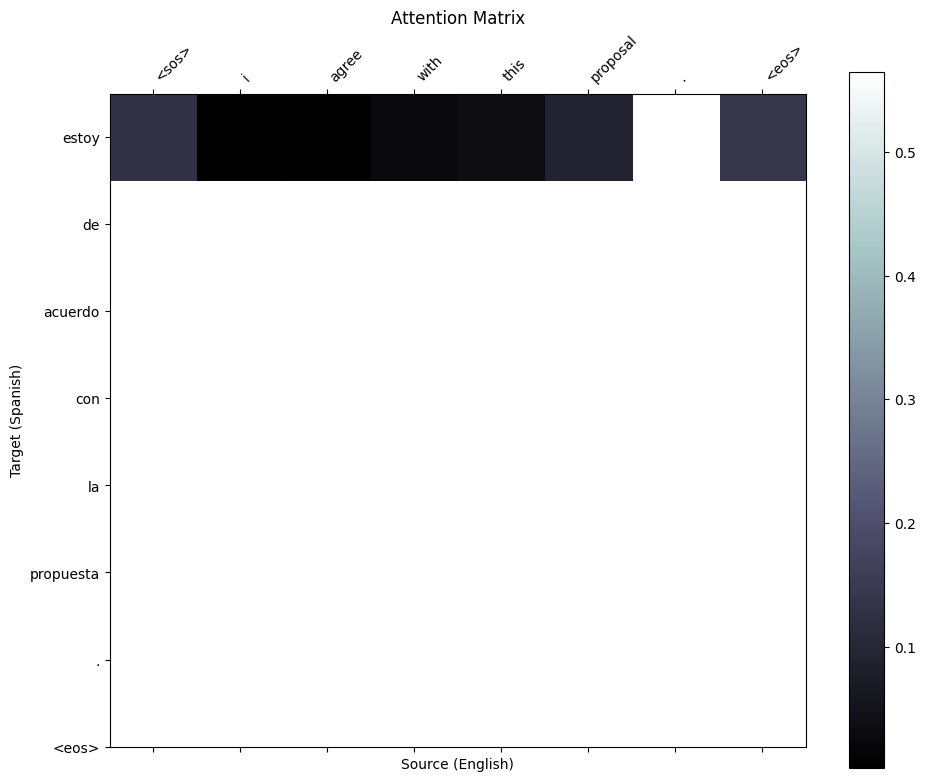

In [25]:
sentence = "I agree with this proposal."
translation, attention = translate_sentence(model, sentence, SRC_VOCAB, TRG_VOCAB, tokenize_en, tokenize_es, device)

print("EN:", sentence)
print("ES:", ' '.join(translation))

display_attention(sentence, translation, attention)

**CONCLUSION**

# Аналіз результатів навчання моделі Seq2Seq з механізмом уваги
**(англійська → іспанська)**

## 1. Параметри експерименту

- Датасет: Helsinki-NLP/europarl (en-es)
- Кількість прикладів: 12 000
- Розмір батчу: 16
- Embedding dim: 128
- Hidden dim: 256
- Кількість шарів: 1
- Кількість епох: 3
- Оптимізатор: Adam
- Функція втрат: CrossEntropyLoss

## 2. Аналіз функції втрат

| Епоха | Train Loss | Val Loss |
|-------|------------|----------|
| 1     | 5.909      | 6.054    |
| 2     | 5.289      | 5.757    |
| 3     | 4.841      | 5.515    |

Функція втрат стабільно зменшувалася як на навчальній, так і на валідаційній вибірках. Це свідчить про те, що модель успішно навчалася. Сильного перенавчання не спостерігалося — Validation Loss також падав протягом усіх трьох епох.

Абсолютні значення loss залишаються досить високими через обмежену кількість епох, зменшений обсяг даних та спрощену архітектуру моделі.

## 3. Аналіз механізму уваги

Візуалізація матриці уваги на реченні «I agree with this proposal» показала майже однорідний розподіл ваг. Це очікуваний результат після лише 3 епох навчання — механізм уваги ще не встиг сформувати чіткі та інтерпретовані зв’язки між словами оригіналу та перекладу.

Зі збільшенням кількості епох attention зазвичай стає більш «гострим» і починає виділяти семантично важливі слова.

## 4. Якість перекладу

Якість згенерованих перекладів наразі низька. Окремі речення частково зберігають зміст (наприклад, «I agree with this proposal» → «estoy de acuerdo con la propuesta»), однак більшість перекладів містять повтори та втрату змісту.

Це закономірно при обмежених ресурсах навчання.

## 5. Сильні та слабкі сторони моделі

**Сильні сторони:**
- Успішно реалізовано архітектуру Seq2Seq з Attention
- Loss стабільно зменшується
- Відсутнє явне перенавчання
- Код повністю робочий

**Слабкі сторони:**
- Низька якість перекладу
- Attention ще слабо сформований
- Модель чутлива до обмежень пам’яті (CPU)
- Наявність повторів у генерації